# 03 — Benchmark lineal de regresión (TCH y %Sac.Caña)

**Objetivo:** benchmark de regresión lineal múltiple **interpretada** (enunciado del taller, modelos de referencia): métricas en CV y
hold-out, significancia, signo y magnitud de los coeficientes, VIF y diagnóstico de supuestos (linealidad,
homocedasticidad, normalidad). Después se compara con Ridge y Lasso para ver si la regularización mejora la
generalización.

- Split, filtros y preprocesador salen de `src/` (verificados en el notebook 02). Funciones de evaluación: `src/evaluacion.py`.
- CV: `GroupKFold(5)` por suerte sobre train (`CV_GRUPOS`); el preprocesador se reajusta en cada fold.
- Métricas: R², RMSE y MAE. Un R² > 0.9 se trata como alarma de leakage.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
from src.datos import CV_GRUPOS, particiones_regresion, preparar_xy
from src.evaluacion import (COLORES, ajustar_ols, evaluar, grafico_diagnostico, metricas, pruebas_supuestos,
                            tabla_coeficientes, vif)
from src.preprocesamiento import PRECOSECHA, construir_preprocesador

# Categorías de test que no aparecen en train → van a la categoría "infrequent" (comportamiento buscado)
warnings.filterwarnings("ignore", message="Found unknown categories")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

## 0. Control: subconjunto con precosecha y descarte de la columna

Antes de definir las variantes se comprueba que:
1. `preparar_xy(..., con_precosecha=True)` deja **solo** las filas de 2017–2021 con `Sac.Caña Precosecha` > 0
   (y con target), y qué columnas devuelve según el flag.
2. `construir_preprocesador("lineal", con_precosecha=False)` descarta esa columna (`remainder="drop"`) sin error,
   y su salida es idéntica a la que da cuando la columna no está en X.

In [2]:
train, test = particiones_regresion()
X, X_sin_flag = {}, {}
for nombre, part in [("train", train), ("test", test)]:
    X[nombre], y_pre, _ = preparar_xy(part, "%Sac.Caña", con_precosecha=True)
    X_sin_flag[nombre] = preparar_xy(part, "%Sac.Caña", con_precosecha=False)[0]
    # 1. Filtro de filas: se recalcula la máscara a mano y se compara
    esperado = part["%Sac.Caña"].notna() & (part["Período"] // 100 <= 2021) & part["Sac.Caña Precosecha"].gt(0) & part["Sac.Caña Precosecha"].le(25)
    assert len(X[nombre]) == esperado.sum() and y_pre.notna().all()
    assert X[nombre][PRECOSECHA].gt(0).all() and X[nombre][PRECOSECHA].le(25).all() and X[nombre]["Período"].floordiv(100).le(2021).all()

# 2. Preprocesador SIN precosecha, ajustado (fit solo en train) sobre un X que SÍ trae la columna
pre_sin = construir_preprocesador("lineal", con_precosecha=False).fit(X["train"])
pre_con = construir_preprocesador("lineal", con_precosecha=True).fit(X["train"])
# Referencia: el mismo preprocesador con la columna quitada a mano → la salida debe ser idéntica
ref = construir_preprocesador("lineal", con_precosecha=False).fit(X["train"].drop(columns=PRECOSECHA))

filas = []
for nombre in ["train", "test"]:
    Z_sin, Z_con = pre_sin.transform(X[nombre]), pre_con.transform(X[nombre])
    pd.testing.assert_frame_equal(Z_sin, ref.transform(X[nombre].drop(columns=PRECOSECHA)))
    assert PRECOSECHA not in Z_sin.columns and list(Z_con.columns) == list(Z_sin.columns) + [PRECOSECHA]
    part = train if nombre == "train" else test
    filas.append({
        "partición": nombre,
        "filas totales": len(part),
        "filas con %Sac": part["%Sac.Caña"].notna().sum(),
        "filas subconjunto (preparar_xy)": len(X[nombre]),
        "años en subconjunto": f"{X[nombre]['Período'].min() // 100}–{X[nombre]['Período'].max() // 100}",
        "precosecha mín.": X[nombre][PRECOSECHA].min(),
        f"{PRECOSECHA} en X (flag=True)": PRECOSECHA in X[nombre].columns,
        f"{PRECOSECHA} en X (flag=False)": PRECOSECHA in X_sin_flag[nombre].columns,
        "features pre(sin)": Z_sin.shape[1],
        "features pre(con)": Z_con.shape[1],
        "precosecha en salida pre(sin)": PRECOSECHA in Z_sin.columns,
        "NaN en salida pre(sin)": int(Z_sin.isna().sum().sum()),
    })
control = pd.DataFrame(filas).set_index("partición").T
control

partición,train,test
filas totales,16599,4105
filas con %Sac,16472,4076
filas subconjunto (preparar_xy),7317,1794
años en subconjunto,2017–2021,2017–2021
precosecha mín.,9.6,10.71
Sac.Caña Precosecha en X (flag=True),True,True
Sac.Caña Precosecha en X (flag=False),False,False
features pre(sin),80,80
features pre(con),81,81
precosecha en salida pre(sin),False,False


## 1. Variantes

Las cuatro salen de las **mismas** particiones train/test.

| Variante | Filas | Preprocesador |
|---|---|---|
| `TCH` | todas con TCH | sin precosecha |
| `%Sac` | todas con %Sac | sin precosecha |
| `%Sac sub. sin pre` | subconjunto 2017–2021 con precosecha > 0 | sin precosecha (la columna llega en X y el preprocesador la descarta, §0) |
| `%Sac sub. + pre` | el mismo subconjunto | con precosecha |

El aporte de `Sac.Caña Precosecha` se mide entre las dos últimas, que comparten filas. Su R² **no** es comparable
con el de `%Sac` (otra población: solo 2017–2021, donde la precosecha tiene dato real).

In [3]:
# nombre → (target, filas del subconjunto con precosecha, precosecha entra al preprocesador)
VARIANTES = {
    "TCH": ("TCH", False, False),
    "%Sac": ("%Sac.Caña", False, False),
    "%Sac sub. sin pre": ("%Sac.Caña", True, False),
    "%Sac sub. + pre": ("%Sac.Caña", True, True),
}
CLAVE_FIG = {"TCH": "tch", "%Sac": "sac", "%Sac sub. sin pre": "sac_sub", "%Sac sub. + pre": "sac_pre"}

datos = {}
for nombre, (target, subconjunto, _) in VARIANTES.items():
    X_tr, y_tr, g_tr = preparar_xy(train, target, subconjunto)
    X_te, y_te, g_te = preparar_xy(test, target, subconjunto)
    assert not set(g_tr) & set(g_te), "hay suertes en train y en test"
    datos[nombre] = (X_tr, y_tr, g_tr, X_te, y_te)

def pipeline(nombre, modelo):
    return Pipeline([("pre", construir_preprocesador("lineal", VARIANTES[nombre][2])), ("modelo", modelo)])

tamanos = pd.DataFrame({n: {"n_train": len(d[0]), "n_test": len(d[3]), "suertes_train": d[2].nunique()}
                        for n, d in datos.items()}).T
display(tamanos)

# Las 3 variantes que ya existían: mismo n que el notebook 02
for nombre, (n_tr, n_te) in {"TCH": (16_599, 4_105), "%Sac": (16_472, 4_076), "%Sac sub. + pre": (7_317, 1_794)}.items():
    assert (tamanos.loc[nombre, "n_train"], tamanos.loc[nombre, "n_test"]) == (n_tr, n_te), nombre
# La variante nueva: mismas filas que la 4.ª (solo cambia si la precosecha entra al preprocesador)
assert (tamanos.loc["%Sac sub. sin pre"] == tamanos.loc["%Sac sub. + pre"]).all()

,n_train,n_test,suertes_train
TCH,16599,4105,4608
%Sac,16472,4076,4598
%Sac sub. sin pre,7317,1794,2869
%Sac sub. + pre,7317,1794,2869


## 2. `LinearRegression`: CV por grupos + hold-out

`brecha_*` = CV − test. Una brecha grande indica sobreajuste o que el test difiere de train.

In [4]:
res_lr = {n: evaluar(pipeline(n, LinearRegression()), *datos[n]) for n in VARIANTES}
tabla_lr = pd.DataFrame({n: r["metricas"] for n, r in res_lr.items()}).T
display(tabla_lr.round(3))
assert (tabla_lr[["R2_cv", "R2_test"]] < 0.9).all().all(), "R² sospechoso: revisar leakage"
# Mismo R² CV que el smoke test del notebook 02 (valores redondeados a 3 decimales)
assert np.allclose(tabla_lr.loc[["TCH", "%Sac", "%Sac sub. + pre"], "R2_cv"], [0.328, 0.387, 0.417], atol=5e-4)

,R2_cv,R2_cv_sd,RMSE_cv,RMSE_cv_sd,MAE_cv,MAE_cv_sd,R2_test,brecha_R2,RMSE_test,brecha_RMSE,MAE_test,brecha_MAE
TCH,0.328,0.022,26.588,0.682,20.415,0.552,0.314,0.013,26.118,0.470,20.017,0.398
%Sac,0.387,0.013,0.898,0.016,0.691,0.011,0.370,0.017,0.906,-0.009,0.689,0.001
%Sac sub. sin pre,0.373,0.010,0.805,0.006,0.628,0.008,0.337,0.036,0.839,-0.033,0.636,-0.009
%Sac sub. + pre,0.417,0.014,0.776,0.007,0.602,0.007,0.377,0.040,0.813,-0.036,0.614,-0.012


**Lectura (§2).**
- **TCH:** R² CV 0.328 ± 0.022 y R² test 0.314. RMSE de 26.6 t/ha en CV y 26.1 en test; MAE de ~20 t/ha. El RMSE de
  test no es peor que el de CV (brecha +0.47 t/ha): **no hay sobreajuste**. La diferencia de R² (0.013) viene de que
  el test tiene menos varianza, no de un error mayor. El modelo lineal explica alrededor de un tercio de la
  variabilidad del TCH.
- **%Sac:** R² CV 0.387, test 0.370; RMSE 0.90 puntos de sacarosa y MAE 0.69. CV y test coinciden.
- **Precosecha (misma población, 2017–2021):** R² CV 0.373 → **0.417** (+0.044) y R² test 0.337 → 0.377 (+0.040);
  RMSE CV de 0.805 → 0.776 (−3.6 %). La mejora es **moderada** para un proxy casi directo del target. El muestreo
  precosecha se hace semanas antes del corte, así que la maduración y la fecha de cosecha siguen moviendo la sacarosa
  después de esa medición.
- En el subconjunto el test sale ~0.04 de R² peor que la CV en **las dos** variantes por igual. Es una propiedad de
  esa partición (1 794 filas), no de la precosecha.
- Ningún R² se acerca a 0.9: no hay señal de leakage.

## 3. Inferencia: OLS con errores estándar cluster-robustos por suerte

Los coeficientes son los mismos que los de `LinearRegression` (se comprueba). Lo que cambia es el error estándar:
se agrupa por suerte (≈3.6 registros por suerte no son independientes) y es robusto a heterocedasticidad.

Cómo leer la magnitud:
- **Numéricas** (estandarizadas, las lluvias además con `log1p`): cambio en el target por **+1 desvío estándar** de la variable.
- **Dummies**: diferencia frente a la categoría de referencia (la primera alfabéticamente; la eliminada por `drop="first"`).
- **Flags** (`tiene_registro_riego`, `tiene_dato_climatico`, `missingindicator_*`): diferencia entre tener y no tener el dato.
- **Spline de `Semanas mad.`**: sus bases no se interpretan una por una; se grafica la curva de efecto (§3.1).

In [5]:
def tipo_columna(c):
    if c.startswith("Semanas mad._sp"):
        return "spline"
    if c.startswith("missingindicator_") or c in ("tiene_registro_riego", "tiene_dato_climatico"):
        return "flag"
    if "_" in c and c.split("_")[0] in ("Variedad", "Suelo", "Zona", "Producto", "T.Corte", "Tenencia", "Cultivo", "mes"):
        return "dummy"
    return "numérica (1 sd)"

ols, coefs, Z_train = {}, {}, {}
for nombre in VARIANTES:
    X_tr, y_tr, g_tr = datos[nombre][:3]
    ols[nombre], Z_train[nombre] = ajustar_ols(construir_preprocesador("lineal", VARIANTES[nombre][2]), X_tr, y_tr, g_tr)
    lr = res_lr[nombre]["modelo"].named_steps["modelo"]
    assert np.allclose(ols[nombre].params.drop("const"), lr.coef_, rtol=1e-6, atol=1e-8), nombre
    assert np.isclose(ols[nombre].params["const"], lr.intercept_), nombre
    t = tabla_coeficientes(ols[nombre])
    t.insert(0, "tipo", t.index.map(tipo_columna))
    coefs[nombre] = t
print("Coeficientes OLS == LinearRegression en las 4 variantes ✔")

resumen = pd.DataFrame({n: {"R2 (train)": o.rsquared, "R2 ajustado": o.rsquared_adj, "n": int(o.nobs),
                            "coeficientes": len(o.params) - 1,
                            "significativos (p<0.05)": int((coefs[n]["p_value"] < 0.05).sum())}
                        for n, o in ols.items()}).T
resumen

Coeficientes OLS == LinearRegression en las 4 variantes ✔


,R2 (train),R2 ajustado,n,coeficientes,significativos (p<0.05)
TCH,0.341011,0.337739,16599.0,82.0,48.0
%Sac,0.395393,0.392368,16472.0,82.0,36.0
%Sac sub. sin pre,0.390778,0.384043,7317.0,80.0,40.0
%Sac sub. + pre,0.433533,0.427191,7317.0,81.0,38.0


In [6]:
def significativos(nombre, top=15, excluir=("spline",)):
    t = coefs[nombre]
    t = t[(t["p_value"] < 0.05) & ~t["tipo"].isin(excluir)]
    return t.reindex(t["coef"].abs().sort_values(ascending=False).index).head(top)

for nombre in ["TCH", "%Sac"]:
    print(f"— {nombre}: coeficientes significativos (p < 0.05), ordenados por |coef| —")
    display(significativos(nombre).round(4))

— TCH: coeficientes significativos (p < 0.05), ordenados por |coef| —


,tipo,coef,ee_cluster,p_value,ic_inf,ic_sup
Suelo_CERRITO,dummy,-22.4060,4.7715,0.0000,-31.7579,-13.0541
Variedad_CC05-430,dummy,21.9214,2.9935,0.0000,16.0542,27.7886
Zona_IP02,dummy,15.5168,1.5563,0.0000,12.4665,18.5672
Suelo_SANTA ROSA,dummy,15.3609,4.7202,0.0011,6.1095,24.6122
Variedad_CC85-92,dummy,-14.3463,2.9039,0.0000,-20.0379,-8.6548
Suelo_PALMICHE,dummy,14.2567,4.9818,0.0042,4.4925,24.0209
Variedad_V71-51,dummy,-14.0874,3.7226,0.0002,-21.3835,-6.7913
Suelo_GALPON,dummy,13.5739,4.1384,0.0010,5.4628,21.6851
Suelo_PALMERAS,dummy,13.4220,4.7027,0.0043,4.2050,22.6391
Zona_IP03,dummy,12.4135,1.5713,0.0000,9.3337,15.4933


— %Sac: coeficientes significativos (p < 0.05), ordenados por |coef| —


,tipo,coef,ee_cluster,p_value,ic_inf,ic_sup
Cultivo_Organico,dummy,-0.9867,0.0596,0.0000,-1.1035,-0.8700
Variedad_RB73-2223,dummy,-0.7586,0.0829,0.0000,-0.9210,-0.5962
Variedad_CC93-4181,dummy,0.6769,0.1031,0.0000,0.4748,0.8789
mes_cosecha_10,dummy,0.6643,0.0349,0.0000,0.5959,0.7326
mes_cosecha_9,dummy,0.5254,0.0360,0.0000,0.4549,0.5959
Suelo_CERRITO-NIMA,dummy,-0.4706,0.1217,0.0001,-0.7091,-0.2322
Variedad_CC05-430,dummy,-0.4502,0.0765,0.0000,-0.6002,-0.3003
T.Corte_NO DEF.,dummy,-0.4372,0.0647,0.0000,-0.5640,-0.3104
mes_cosecha_6,dummy,-0.3721,0.0350,0.0000,-0.4406,-0.3036
Producto_infrequent_sklearn,dummy,-0.3694,0.0518,0.0000,-0.4710,-0.2678


In [7]:
# Numéricas: todas, con su p-value (incluye las no significativas: también informan)
num = pd.concat({n: coefs[n].loc[coefs[n]["tipo"] == "numérica (1 sd)", ["coef", "p_value"]] for n in ["TCH", "%Sac"]}, axis=1)
num.round(4)

TCH            %Sac        
                           coef p_value    coef p_value
Lluvias (2 Meses Ant.)   0.1034  0.7162 -0.2301  0.0000
Lluvias 0 -3            -1.7255  0.0000  0.0261  0.0020
Lluvias tres a seis     -1.1946  0.0000 -0.0102  0.2595
Lluvias seis a nueve    -0.2584  0.2893  0.0136  0.0936
Luvias 9 -FC             1.8067  0.0000  0.1098  0.0000
Dosis Madurante         -1.4610  0.0162  0.0135  0.4864
DDUlt.Riego              0.6237  0.0338 -0.0373  0.0000
Edad Ult Cos            10.0334  0.0000  0.0495  0.0000
Cod.Estado #            -1.8000  0.0000  0.0200  0.0627
Dist Km                 -3.5030  0.0000 -0.0195  0.1294
anio                    -7.9364  0.0000  0.0499  0.0000
M3 Riego                 2.9441  0.0000 -0.0101  0.2522

In [8]:
# Aporte de la precosecha: misma población, con y sin la variable
sub = pd.concat({n: coefs[n].loc[coefs[n]["tipo"] == "numérica (1 sd)", ["coef", "p_value"]]
                 for n in ["%Sac sub. sin pre", "%Sac sub. + pre"]}, axis=1)
display(sub.round(4))
print(f"Coeficiente de {PRECOSECHA}: {coefs['%Sac sub. + pre'].loc[PRECOSECHA, 'coef']:.3f} puntos de %Sac por +1 sd "
      f"(sd de train = {datos['%Sac sub. + pre'][0][PRECOSECHA].std():.2f}), p = {coefs['%Sac sub. + pre'].loc[PRECOSECHA, 'p_value']:.2g}")

%Sac sub. sin pre         %Sac sub. + pre        
                                    coef p_value            coef p_value
Lluvias (2 Meses Ant.)           -0.1742  0.0000         -0.1673  0.0000
Lluvias 0 -3                      0.0212  0.0546          0.0144  0.1847
Lluvias tres a seis               0.0081  0.4812          0.0031  0.7847
Lluvias seis a nueve              0.0417  0.0004          0.0341  0.0029
Luvias 9 -FC                      0.0416  0.0363          0.0522  0.0041
Dosis Madurante                   0.0368  0.1618          0.0349  0.1656
DDUlt.Riego                      -0.0364  0.0017         -0.0366  0.0009
Edad Ult Cos                     -0.0656  0.0000         -0.0660  0.0000
Cod.Estado #                      0.0433  0.0030          0.0268  0.0608
Dist Km                          -0.0361  0.0212         -0.0387  0.0096
anio                              0.1871  0.0000          0.1722  0.0000
M3 Riego                          0.0129  0.2510          0.0115  0.2832
Sac.Caña Precosecha                  NaN     NaN          0.2324  0.0000

Coeficiente de Sac.Caña Precosecha: 0.232 puntos de %Sac por +1 sd (sd de train = 1.07), p = 1.2e-99


**Lectura (§3).** Son asociaciones condicionales (manteniendo el resto constante), no efectos causales. Los p-values
usan errores estándar cluster-robustos por suerte.

*TCH, numéricas:*
- **`Edad Ult Cos`** es la numérica más influyente: **+10.0 t/ha por desvío** (sd = 1.9 meses → ~5.3 t/ha por mes
  adicional de ciclo). Coincide con lo reportado para el sector: cortar con < 12 meses reduce la productividad.
- **`anio`** da −7.9 t/ha por desvío (sd = 2.2 años): la productividad cae a lo largo de 2017–2024, también en
  línea con la caída de productividad reportada para el sector. El modelo no distingue si se debe al clima o al manejo.
- **`Dist Km`** (−3.5 por desvío de 18 km) y **`Cod.Estado #`** (−1.8 por desvío de 4.2 cortes: la cepa se desgasta)
  van en la dirección esperada. `Dist Km` es un proxy logístico: probablemente capta el tipo de proveedor, más que
  la distancia en sí.
- **`M3 Riego`** da +2.9 por desvío (riego de precisión del Ingenio).
- **Lluvias:** el signo cambia según la ventana (0–3 y 3–6 negativas; 9-FC positiva). Están imputadas (Zona × mes) y
  en escala log, y su vacío se concentra en ciertas tenencias, así que su lectura es frágil.
- **`Dosis Madurante`** (−1.5, p = 0.016) va en la dirección de un compromiso maduración ↔ crecimiento (ver §3.1),
  pero con VIF de 8 y en conjunto con `Producto`.

*TCH, categóricas:* son las de mayor magnitud. **`Zona`** IP02/IP03/IP05 dan +11 a +16 t/ha frente a IP01. En
**`Variedad`**, CC05-430 da +22 y CC85-92, V71-51 y CC93-4418 dan entre −12 y −14. **`Suelo`** da diferencias de
±10–22 t/ha. Las referencias de Variedad (CC01-1228) y de Suelo (AMAIME) son categorías raras (~1 % de las filas):
la magnitud de cada dummy se mide contra un grupo pequeño. Por eso conviene comparar las dummies **entre sí** y no
leer cada valor en absoluto; los errores estándar de suelo (~4.7 t/ha) reflejan eso.

*%Sac:*
- Dominan las categóricas. **Orgánico: −0.99 puntos** frente a Normal (es el efecto más grande).
- Variedad: RB73-2223 da −0.76 y CC93-4181, +0.68.
- **Mes de cosecha:** septiembre y octubre dan +0.53/+0.66 y junio, −0.37 (todos frente a enero). Es la época de
  cosecha que se reporta para la maduración de la caña.
- **Corte mecanizado:** −0.34 frente a manual.
- Productos distintos de BONUS: −0.35/−0.37.
- Entre las numéricas, la lluvia de los **2 meses previos** a la cosecha es la de mayor peso: **−0.23 por desvío**
  (lluvia justo antes del corte, asociada con menos sacarosa). `9 -FC` da +0.11.

*Precosecha:* +0.23 puntos de %Sac por desvío (sd = 1.07 → ~0.22 puntos por punto de precosecha), p ≈ 1e-99. Los demás
coeficientes del subconjunto casi no cambian al agregarla: aporta información que el resto de variables no tenía,
sin desplazar a ninguna.

### 3.1 Efecto de `Semanas mad.` (spline)

Curva = Σ βₖ·Bₖ(semanas) − valor en la semana de referencia, con banda de ±1.96 EE (método delta con la matriz de
covarianza cluster-robusta de los coeficientes del spline). La referencia es la **semana 4**: el 0 corresponde casi
siempre a "no madurada", que ya captura la dummy de `Producto`. Se grafica hasta el p99 de las semanas de los
lotes madurados en train. La hipótesis previa (literatura sobre maduración química) es una U invertida con el óptimo en 8–16 semanas.

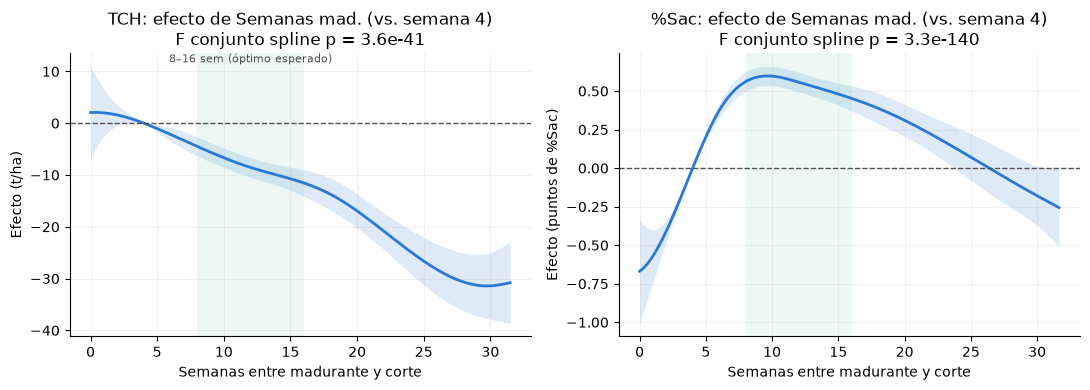

In [9]:
def efecto_semanas(nombre, ref=4.0):
    pre = res_lr[nombre]["modelo"].named_steps["pre"]
    spline = pre.named_steps["columnas"].named_transformers_["semanas"].steps[-1][1]
    X_tr = datos[nombre][0]
    semanas = X_tr.loc[X_tr["Producto"].notna(), "Semanas mad."]
    grilla = np.linspace(0, semanas.clip(lower=0).quantile(0.99), 200)
    B = np.asarray(spline.transform(pd.DataFrame({"Semanas mad.": np.r_[grilla, ref]})), dtype=float)
    B = B[:-1] - B[-1]
    cols = [c for c in coefs[nombre].index if c.startswith("Semanas mad._sp")]
    beta, cov = ols[nombre].params[cols].to_numpy(), ols[nombre].cov_params().loc[cols, cols].to_numpy()
    efecto = B @ beta
    ee = np.sqrt(np.einsum("ij,jk,ik->i", B, cov, B))
    R = (ols[nombre].params.index.to_numpy()[None, :] == np.array(cols)[:, None]).astype(float)
    return grilla, efecto, ee, float(ols[nombre].f_test(R).pvalue)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nombre, unidad) in zip(axes, [("TCH", "t/ha"), ("%Sac", "puntos de %Sac")]):
    g, e, ee, p = efecto_semanas(nombre)
    ax.fill_between(g, e - 1.96 * ee, e + 1.96 * ee, color=COLORES["serie1"], alpha=0.15, lw=0)
    ax.plot(g, e, color=COLORES["serie1"], lw=2)
    ax.axhline(0, color=COLORES["tinta"], lw=1, ls="--")
    ax.axvspan(8, 16, color=COLORES["serie3"], alpha=0.08, lw=0)
    ax.set(title=f"{nombre}: efecto de Semanas mad. (vs. semana 4)\nF conjunto spline p = {p:.2g}",
           xlabel="Semanas entre madurante y corte", ylabel=f"Efecto ({unidad})")
    ax.grid(alpha=0.25, lw=0.5)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].text(12, axes[0].get_ylim()[1], "8–16 sem (óptimo esperado)", ha="center", va="top", fontsize=8, color=COLORES["tinta"])
fig.tight_layout()
fig.savefig(FIGURAS / "reg_semanas_mad_efecto.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura (§3.1).**
- **%Sac: U invertida** (prueba F conjunta del spline p ≈ 1e-140). El máximo está en **~10 semanas** (+0.6 puntos frente
  a la semana 4); el efecto se mantiene por encima del nivel de la semana 4 hasta ~26 semanas y después cae. Confirma
  la ventana óptima de 8–16 semanas que se espera por la literatura de maduración y la decisión de conservar la cola > 20 semanas con forma no lineal.
- **TCH: caída monótona** (p ≈ 1e-41): ~−7 t/ha a las 10 semanas y ~−30 t/ha a las 30, frente a la semana 4.
- **Implicación de negocio:** la ventana que maximiza sacarosa (8–16 semanas) cuesta ~5–11 t/ha frente a cortar a las
  4 semanas. Cuál es la mejor depende del objetivo (azúcar por hectárea = TCH × sacarosa), no de un solo target.
- Las bandas son anchas cerca de 0 semanas porque casi ningún lote madurado se corta enseguida. La diferencia entre
  madurado y no madurado la captura la dummy de `Producto`, no la curva.

## 4. Multicolinealidad (VIF)

VIF calculado sobre la matriz que realmente entra al modelo (con dummies, flags y bases del spline). Umbrales
usuales: > 5 moderado y > 10 alto. Las bases del spline tienen VIF alto por construcción (son funciones solapadas
de una sola variable): se reportan aparte y no se tratan como un problema. Interesa sobre todo lo que pasa entre
las ventanas de lluvia, sus indicadores de "sin dato" y el flag de riego.

In [10]:
vifs = {n: vif(Z_train[n]) for n in VARIANTES}
tabla_vif = pd.concat(vifs, axis=1)
tabla_vif.insert(0, "tipo", tabla_vif.index.map(tipo_columna))
altos = tabla_vif[(tabla_vif[list(VARIANTES)] > 5).any(axis=1)].sort_values("TCH", ascending=False)
print("Columnas con VIF > 5 en alguna variante:")
display(altos.round(1))
print("VIF > 10 fuera del spline:")
display(altos[(altos["tipo"] != "spline") & (altos[list(VARIANTES)] > 10).any(axis=1)].round(1))

Columnas con VIF > 5 en alguna variante:


,tipo,TCH,%Sac,%Sac sub. sin pre,%Sac sub. + pre
Semanas mad._sp_1,spline,8889.4,8840.8,46330.5,46339.7
Semanas mad._sp_3,spline,5894.6,5876.0,33574.7,33579.8
Semanas mad._sp_2,spline,4369.6,4342.8,22721.1,22724.4
Semanas mad._sp_4,spline,1584.3,1565.3,7488.9,7490.0
Semanas mad._sp_0,spline,958.8,955.6,4066.3,4066.6
Semanas mad._sp_5,spline,330.1,324.6,1045.0,1045.2
Semanas mad._sp_6,spline,271.0,270.8,332.9,332.9
Producto_NO APLICADO,dummy,127.5,128.0,320.8,320.8
Variedad_CC01-1940,dummy,23.1,22.9,20.3,20.3
Suelo_infrequent_sklearn,dummy,17.9,18.2,16.6,16.6


VIF > 10 fuera del spline:


,tipo,TCH,%Sac,%Sac sub. sin pre,%Sac sub. + pre
Producto_NO APLICADO,dummy,127.5,128.0,320.8,320.8
Variedad_CC01-1940,dummy,23.1,22.9,20.3,20.3
Suelo_infrequent_sklearn,dummy,17.9,18.2,16.6,16.6
Suelo_Desconocido,dummy,17.2,17.5,11.5,11.5
Suelo_CORINTIAS,dummy,17.0,17.3,15.0,15.0
Variedad_CC85-92,dummy,15.2,15.2,17.4,17.5
missingindicator_Luvias 9 -FC,flag,12.5,12.5,14.6,14.7
Suelo_GALPON,dummy,11.2,11.4,10.3,10.3
Variedad_CC05-430,dummy,10.6,10.5,2.7,2.8
missingindicator_Lluvias (2 Meses Ant.),flag,10.4,10.5,10.6,10.7


**Lectura (§4).**
- **Spline:** el VIF de sus bases (miles) es estructural. Antes del ajuste del nodo final (100 → 40 semanas) llegaba
  a 1e9 (por eso el último nodo del spline pasó de 100 a 40 semanas).
- **`Producto_NO APLICADO`** (VIF 128; 316 en el subconjunto) hereda esa colinealidad: todas las filas no maduradas
  tienen `Semanas mad.` = 0 y comparten el mismo vector de bases. Su coeficiente **no se interpreta solo**: el efecto
  del madurante se lee junto con la curva de §3.1.
- **Dummies de categorías grandes** (CC01-1940 23, Suelo infrequent/Desconocido/CORINTIAS ~17, CC85-92 15): el VIF
  alto viene de que la categoría de referencia es rara (~1 %), no de redundancia. Infla el error estándar de esas
  dummies, pero no cambia las predicciones.
- **Indicadores de "sin dato" de lluvia** (10–14): son esperables, porque el vacío viene en bloque por hacienda (EDA §3:
  si el ciclo vale 0, las ventanas también). Una mejora posible para interpretar sería unificarlos en un solo flag;
  no se aplica aquí.
- **Todas las numéricas tienen VIF < 10** (la mayor es `Dosis Madurante`, 8), así que su lectura en §3 es estable.
  No se elimina ninguna variable.

## 5. Diagnóstico de supuestos

Una figura 2×2 por variante:
- **(a) Residuos vs. ajustados** (train) con LOWESS → **linealidad**: la curva debería quedar plana alrededor de 0.
- **(b) Scale-location** → **homocedasticidad**: si la curva sube o baja, la varianza depende del nivel predicho.
- **(c) QQ-plot** → **normalidad** de los residuos, sobre todo en las colas.
- **(d) Real vs. predicho en test** → calidad de la predicción fuera de la muestra.

Debajo van las pruebas formales. Con n de 7 000 a 16 000, cualquier desviación mínima da p ≈ 0, así que **la lectura
principal es la visual** y el p-value solo complementa.

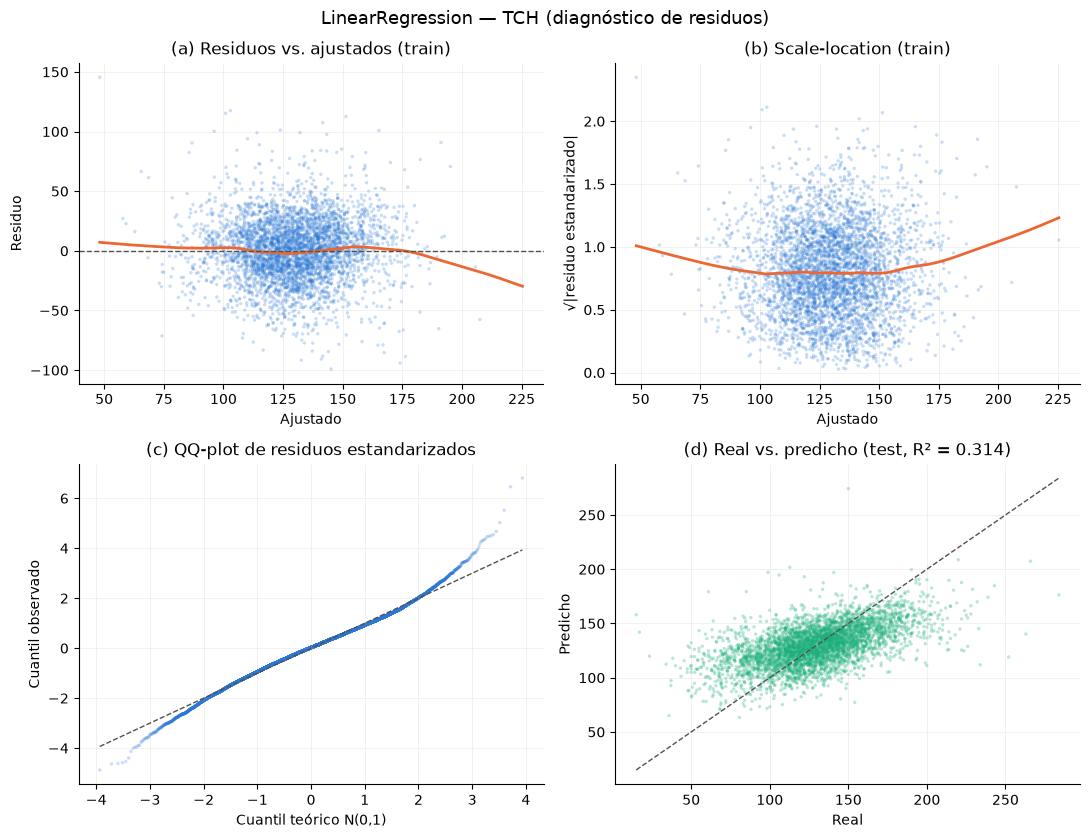

In [11]:
nombre = "TCH"
fig = grafico_diagnostico(ols[nombre], datos[nombre][4], res_lr[nombre]["y_pred_test"],
                          f"LinearRegression — {nombre} (diagnóstico de residuos)")
fig.savefig(FIGURAS / f"reg_lineal_diagnostico_{CLAVE_FIG[nombre]}.png", dpi=150, bbox_inches="tight")
plt.show()

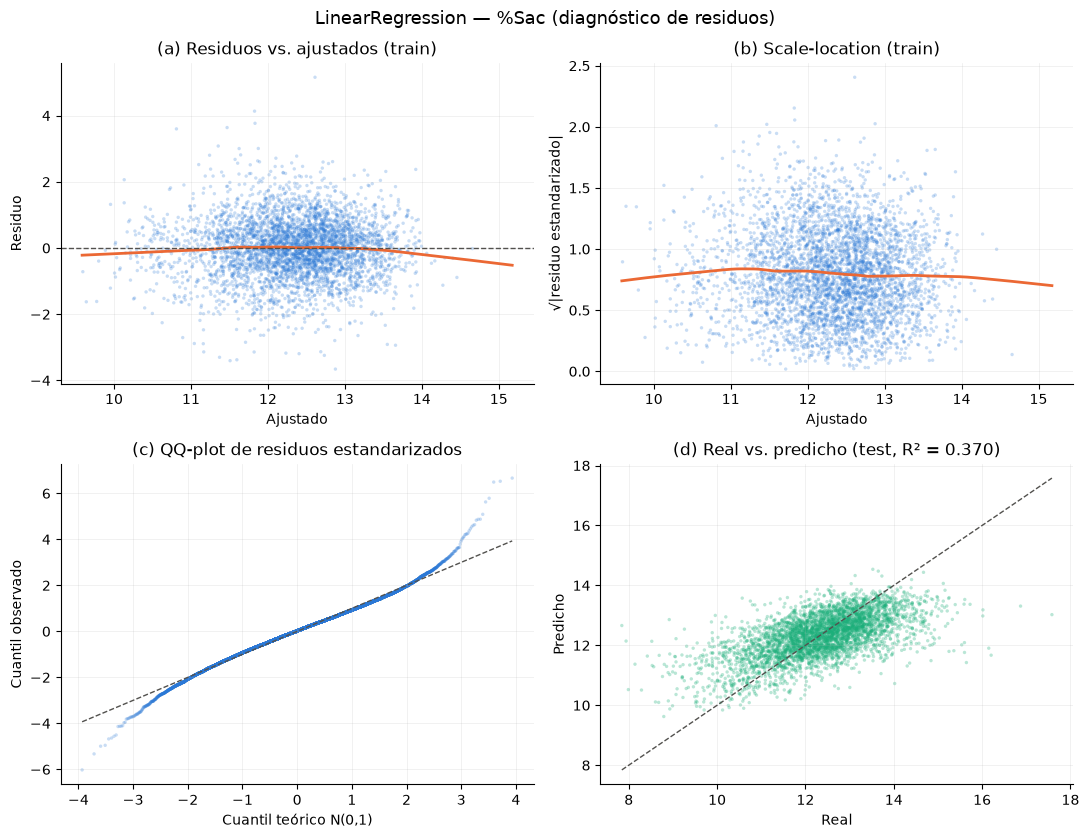

In [12]:
nombre = "%Sac"
fig = grafico_diagnostico(ols[nombre], datos[nombre][4], res_lr[nombre]["y_pred_test"],
                          f"LinearRegression — {nombre} (diagnóstico de residuos)")
fig.savefig(FIGURAS / f"reg_lineal_diagnostico_{CLAVE_FIG[nombre]}.png", dpi=150, bbox_inches="tight")
plt.show()

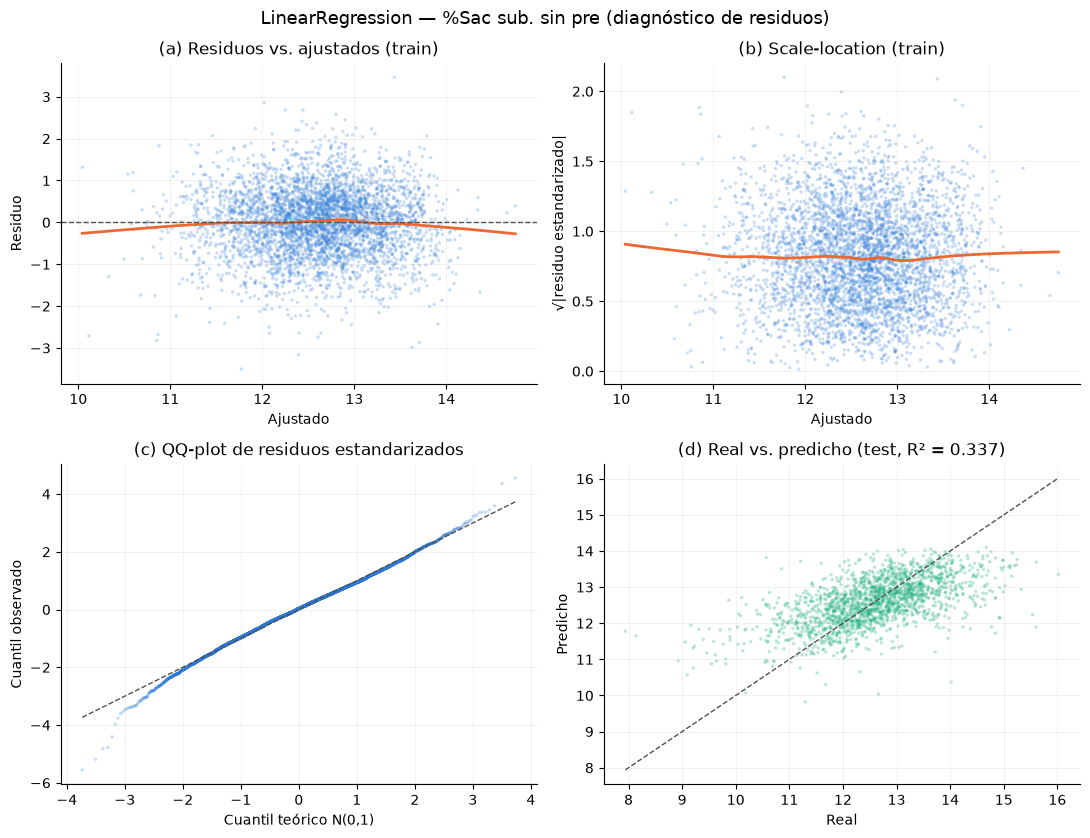

In [13]:
nombre = "%Sac sub. sin pre"
fig = grafico_diagnostico(ols[nombre], datos[nombre][4], res_lr[nombre]["y_pred_test"],
                          f"LinearRegression — {nombre} (diagnóstico de residuos)")
fig.savefig(FIGURAS / f"reg_lineal_diagnostico_{CLAVE_FIG[nombre]}.png", dpi=150, bbox_inches="tight")
plt.show()

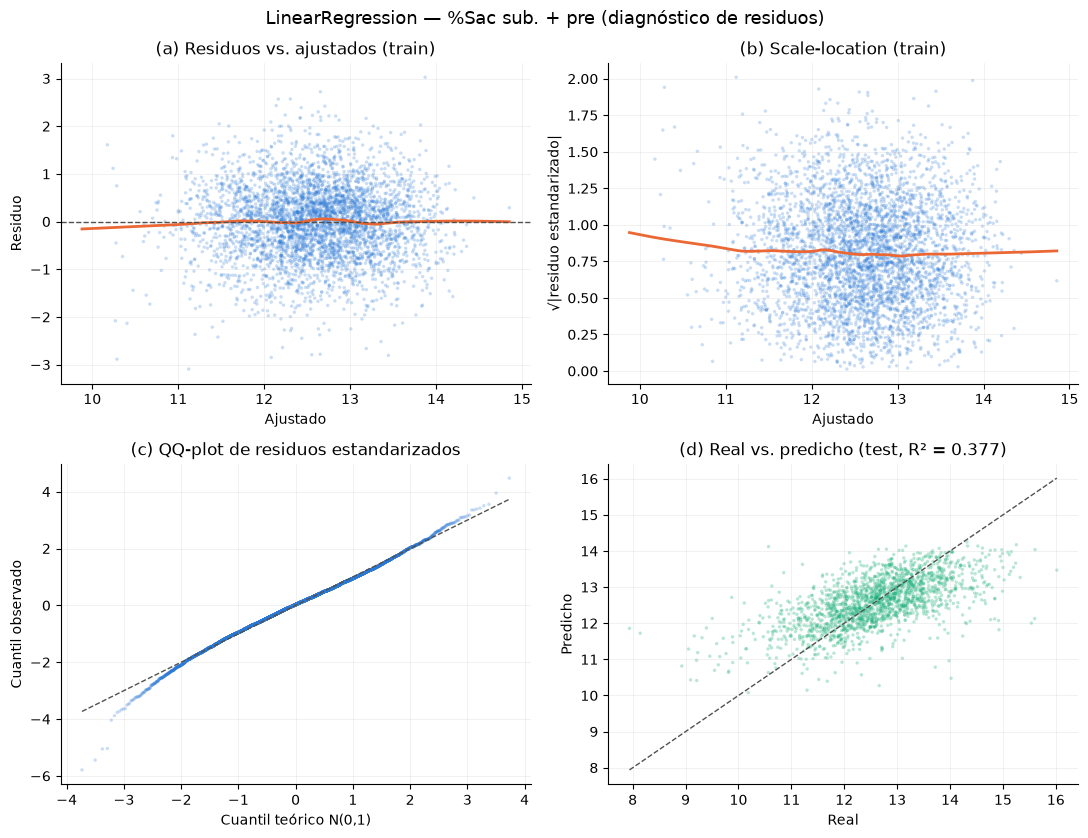

In [14]:
nombre = "%Sac sub. + pre"
fig = grafico_diagnostico(ols[nombre], datos[nombre][4], res_lr[nombre]["y_pred_test"],
                          f"LinearRegression — {nombre} (diagnóstico de residuos)")
fig.savefig(FIGURAS / f"reg_lineal_diagnostico_{CLAVE_FIG[nombre]}.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
supuestos = pd.DataFrame({n: pruebas_supuestos(o) for n, o in ols.items()}).T
supuestos.round(4)

,Breusch-Pagan LM,Breusch-Pagan p,Jarque-Bera,Jarque-Bera p,asimetría,curtosis,Shapiro W (n=5000),Shapiro p,RESET F,RESET p
TCH,913.0967,0.0,1053.5482,0.0,-0.0147,4.2339,0.9895,0.0,46.4345,0.0000
%Sac,716.3503,0.0,1598.6564,0.0,-0.0236,4.5255,0.9928,0.0,33.7719,0.0000
%Sac sub. sin pre,246.9927,0.0,216.7012,0.0,-0.1855,3.7571,0.9946,0.0,8.2614,0.0003
%Sac sub. + pre,247.1103,0.0,267.0787,0.0,-0.1636,3.8769,0.9931,0.0,1.6850,0.1855


**Lectura (§5).**
- **Linealidad.**
  - En TCH la LOWESS es plana en el grueso de los datos (100–175 t/ha). Arriba de 175 baja: son 201 filas (1.2 %) con
    un residuo medio de −5. Por deciles de ajustado, el residuo medio forma una U suave (+3.1 en el primer decil,
    −2.3 en los centrales y +2.5 en el último). Hay una no linealidad leve que RESET detecta (F = 46).
  - En %Sac la LOWESS es plana.
  - En el subconjunto + precosecha, después de quitar los 10 valores imposibles de precosecha, RESET **no rechaza**
    (p = 0.19).
- **Homocedasticidad.**
  - En TCH la varianza crece en los dos extremos de lo ajustado (scale-location en U).
  - En %Sac es casi constante.
  - Breusch-Pagan rechaza en todos los casos, pero con n ≈ 16 000 eso es esperable. Como los errores estándar de §3 son
    cluster-robustos, la heterocedasticidad **no invalida** los p-values.
- **Normalidad.**
  - Los residuos son simétricos (asimetría ≈ 0 en TCH y %Sac) con colas algo pesadas (curtosis 4.2–4.5).
  - En %Sac la cola izquierda pesa más: es el deterioro poscorte (quemas accidentales, vejez), que el modelo no puede
    ver porque esas variables están excluidas por leakage.
  - Con este n, la inferencia sobre los coeficientes es válida por el TCL. La no normalidad afecta sobre todo a
    eventuales intervalos de predicción.
- **Real vs. predicho (d).** Las predicciones se **comprimen** hacia la media.
  - TCH: el real de test va de 15 a 284 t/ha y el 99 % de las predicciones cae entre 80 y 183. La predicción máxima
    (274, con real 150) es la fila de 78.2 meses: aun recortada a 36, su edad sigue muy por encima del resto (el tope
    contiene la extrapolación, pero no la elimina).
  - %Sac: el real va de 7.8 a 17.6 y el 99 % de las predicciones cae entre 10.1 y 13.8. El modelo aditivo no reproduce los extremos. Esa es la limitación
  central del lineal y la razón para probar modelos que capten interacciones (lluvia × suelo × variedad) y no
  linealidades.

### 5.1 Sensibilidad: `log(TCH)`

Las reglas de referencia del curso (§Validación) sugieren: si hay heterocedasticidad, considerar transformar el target. Se ajusta el mismo modelo sobre
`log(TCH)` (`TransformedTargetRegressor`) y se evalúa en la **escala original** (t/ha) para que las métricas
sean comparables. También se repiten las pruebas de residuos, en escala log.

,R2_cv,R2_cv_sd,RMSE_cv,RMSE_cv_sd,MAE_cv,MAE_cv_sd,R2_test,brecha_R2,RMSE_test,brecha_RMSE,MAE_test,brecha_MAE
TCH,0.328,0.022,26.588,0.682,20.415,0.552,0.314,0.013,26.118,0.470,20.017,0.398
log(TCH),0.314,0.027,26.869,0.818,20.669,0.643,0.291,0.022,26.559,0.311,20.267,0.402


,Breusch-Pagan LM,Breusch-Pagan p,Jarque-Bera,Jarque-Bera p,asimetría,curtosis,Shapiro W (n=5000),Shapiro p,RESET F,RESET p
TCH,913.0967,0.0,1053.5482,0.0,-0.0147,4.2339,0.9895,0.0,46.4345,0.0
log(TCH),482.8616,0.0,38437.9177,0.0,-1.2340,10.0346,0.9409,0.0,36.6455,0.0


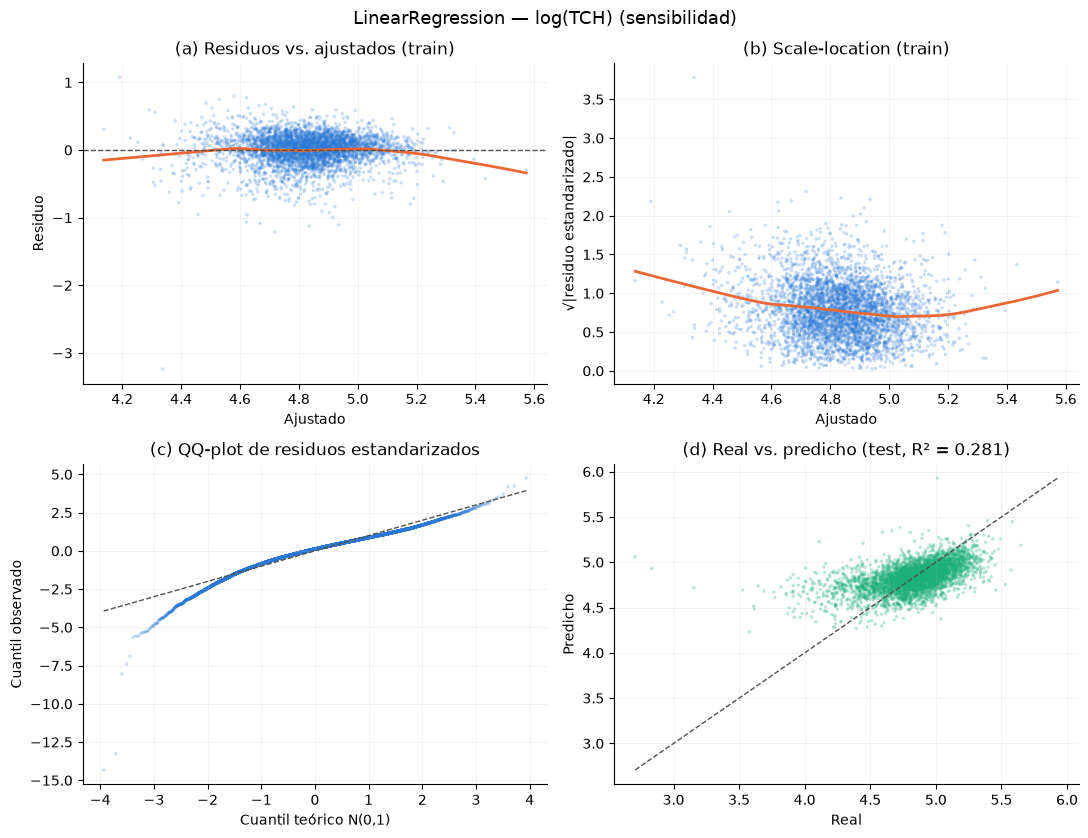

In [16]:
log_tch = TransformedTargetRegressor(regressor=LinearRegression(), func=np.log, inverse_func=np.exp)
res_log = evaluar(pipeline("TCH", log_tch), *datos["TCH"])
display(pd.DataFrame({"TCH": res_lr["TCH"]["metricas"], "log(TCH)": res_log["metricas"]}).T.round(3))

X_tr, y_tr, g_tr = datos["TCH"][:3]
ols_log, _ = ajustar_ols(construir_preprocesador("lineal"), X_tr, np.log(y_tr), g_tr)
display(pd.DataFrame({"TCH": supuestos.loc["TCH"], "log(TCH)": pruebas_supuestos(ols_log)}).T.round(4))
fig = grafico_diagnostico(ols_log, np.log(datos["TCH"][4]), np.log(res_log["y_pred_test"]),
                          "LinearRegression — log(TCH) (sensibilidad)")
plt.show()

**Lectura (§5.1).** `log(TCH)` **no mejora**: R² CV 0.314 frente a 0.328, R² test 0.291 frente a 0.314, y RMSE y MAE peores.
Breusch-Pagan baja (483 frente a 913), pero a costa de residuos muy asimétricos (−1.23) y con curtosis 10, cuando los
de TCH en escala original eran simétricos. **Se mantiene TCH en escala original.** (Antes de recortar `Edad Ult Cos`
a 36 meses, la fila de 78.2 meses hacía explotar esta transformación: R² test −0.66; por eso la edad se recorta a 36 meses.)

## 6. Sensibilidad de los extremos de TCH (regla de negocio literal)

Decisión del EDA (§8): se **conservan** las filas de TCH < 50 o > 250 que no son error de área, y se reporta la
sensibilidad con la regla de negocio literal (eliminar todo TCH < 50 o > 250). El modelo **no** se reentrena: se mide el mismo modelo en test con y sin esas
filas, para ver cuánto del error viene de los extremos.

In [17]:
y_te, y_pred = datos["TCH"][4], res_lr["TCH"]["y_pred_test"]
extremo = ((y_te < 50) | (y_te > 250)).to_numpy()
y_tr = datos["TCH"][1]
print(f"Filas extremas: train {((y_tr < 50) | (y_tr > 250)).sum()}, test {extremo.sum()} "
      f"({extremo.mean():.2%} del test)")
sens = pd.DataFrame({"test completo": metricas(y_te, y_pred),
                     "test sin extremos": metricas(y_te[~extremo], y_pred[~extremo]),
                     "solo extremos": metricas(y_te[extremo], y_pred[extremo])}).T
sens["n"] = [len(y_te), (~extremo).sum(), extremo.sum()]
sens.round(3)

Filas extremas: train 113, test 23 (0.56% del test)


,R2,RMSE,MAE,n
test completo,0.314,26.118,20.017,4105
test sin extremos,0.314,25.444,19.696,4082
solo extremos,0.088,82.768,77.105,23


In [18]:
# Dirección del error en los extremos: ¿el modelo los acerca a la media?
pd.DataFrame({"real": y_te[extremo].to_numpy(), "predicho": y_pred[extremo]}).assign(
    grupo=lambda d: np.where(d["real"] < 50, "TCH < 50", "TCH > 250")).groupby("grupo").agg(
    n=("real", "size"), real_medio=("real", "mean"), predicho_medio=("predicho", "mean")).round(1)

,n,real_medio,predicho_medio
grupo,,,
TCH < 50,19,39.3,110.5
TCH > 250,4,266.2,160.8


**Lectura (§6).** Las 23 filas extremas del test (0.56 %) mueven poco las métricas globales: RMSE 26.12 → 25.44 (−2.6 %),
MAE 20.02 → 19.70 y R² igual (0.314). Pero **el modelo no las detecta**: en ellas el MAE es de 77 t/ha. A las 19 filas
con TCH < 50 (real medio 39) les predice 110 en promedio, y a las 4 con TCH > 250 (real 266), 161. Se mantiene la
decisión de **conservarlas**: son justamente los casos que el Ingenio necesita anticipar. Que el lineal no los
capte es una limitación del modelo, no un motivo para sacarlos del test. Por eso se reporta el MAE junto al RMSE.

## 7. Ridge y Lasso

`GridSearchCV` sobre `alpha` con la misma CV por grupos (`CV_GRUPOS`). El preprocesador va dentro del Pipeline, así
que se reajusta en cada fold. El criterio es el RMSE. El CV del mejor `alpha` es un poco optimista, porque el
`alpha` se eligió con esos mismos folds; la medida sin sesgo es el hold-out. Las numéricas ya están estandarizadas,
de modo que la penalización trata a todas por igual. Las dummies y los flags quedan en escala 0/1: es la convención
habitual y se mantiene tal cual.

In [19]:
GRILLAS = {"Ridge": (Ridge(), np.logspace(-3, 3, 13)),
           "Lasso": (Lasso(max_iter=50_000), np.logspace(-4, 0, 13))}

busquedas, res_reg = {}, {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for modelo, (estimador, alphas) in GRILLAS.items():
        for nombre in VARIANTES:
            X_tr, y_tr, g_tr, X_te, y_te = datos[nombre]
            gs = GridSearchCV(pipeline(nombre, estimador), {"modelo__alpha": alphas}, cv=CV_GRUPOS,
                              scoring="neg_root_mean_squared_error").fit(X_tr, y_tr, groups=g_tr)
            busquedas[(modelo, nombre)] = gs
            alpha = gs.best_params_["modelo__alpha"]
            r = evaluar(pipeline(nombre, estimador.set_params(alpha=alpha)), X_tr, y_tr, g_tr, X_te, y_te)
            r["metricas"]["alpha"] = alpha
            res_reg[(modelo, nombre)] = r

alphas_elegidos = pd.DataFrame({k: {"alpha": v["metricas"]["alpha"],
                                    "en el borde de la grilla": v["metricas"]["alpha"] in GRILLAS[k[0]][1][[0, -1]]}
                                for k, v in res_reg.items()}).T
alphas_elegidos

alpha en el borde de la grilla
Ridge TCH                0.003162                    False
      %Sac               3.162278                    False
      %Sac sub. sin pre  3.162278                    False
      %Sac sub. + pre    3.162278                    False
Lasso TCH                  0.0001                     True
      %Sac                 0.0001                     True
      %Sac sub. sin pre  0.000215                    False
      %Sac sub. + pre    0.000215                    False

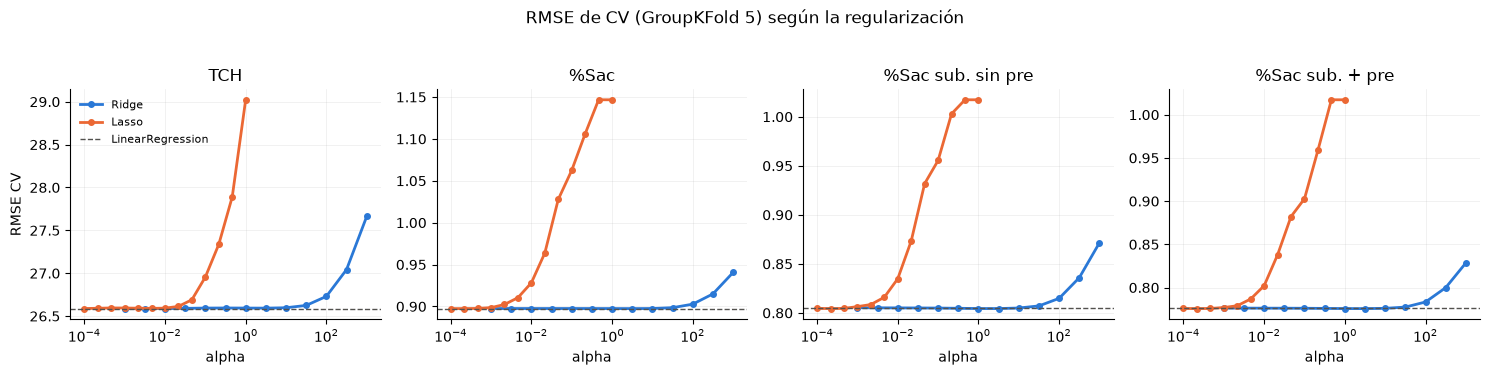

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, nombre in zip(axes, VARIANTES):
    rmse_lr = tabla_lr.loc[nombre, "RMSE_cv"]
    for modelo, color in [("Ridge", COLORES["serie1"]), ("Lasso", COLORES["serie2"])]:
        cvr = busquedas[(modelo, nombre)].cv_results_
        a = cvr["param_modelo__alpha"].data.astype(float)
        ax.plot(a, -cvr["mean_test_score"], color=color, lw=2, marker="o", ms=4, label=modelo)
    ax.axhline(rmse_lr, color=COLORES["tinta"], lw=1, ls="--", label="LinearRegression")
    ax.set_xscale("log")
    ax.set(title=nombre, xlabel="alpha", ylabel="RMSE CV" if nombre == "TCH" else None)
    ax.grid(alpha=0.25, lw=0.5)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("RMSE de CV (GroupKFold 5) según la regularización", y=1.03)
fig.tight_layout()
fig.savefig(FIGURAS / "reg_regularizacion_alpha.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
# Selección de variables de Lasso: coeficientes en 0, contrastados con los p-values de OLS
filas = []
for nombre in VARIANTES:
    lasso = res_reg[("Lasso", nombre)]["modelo"]
    beta = pd.Series(lasso.named_steps["modelo"].coef_, lasso.named_steps["modelo"].feature_names_in_)
    ceros = beta.index[beta == 0]
    p = coefs[nombre]["p_value"].reindex(ceros)
    filas.append({"variante": nombre, "alpha": res_reg[("Lasso", nombre)]["metricas"]["alpha"],
                  "coeficientes": len(beta), "en 0": len(ceros),
                  "en 0 y significativos en OLS (p<0.05)": int((p < 0.05).sum()),
                  "columnas en 0": ", ".join(ceros)})
lasso_ceros = pd.DataFrame(filas).set_index("variante")
display(lasso_ceros.drop(columns="columnas en 0"))
for nombre, fila in lasso_ceros.iterrows():
    print(f"{nombre}: {fila['columnas en 0'] or '(ninguna)'}")

,alpha,coeficientes,en 0,en 0 y significativos en OLS (p<0.05)
variante,,,,
TCH,0.000100,82,0,0
%Sac,0.000100,82,5,0
%Sac sub. sin pre,0.000215,80,7,0
%Sac sub. + pre,0.000215,81,5,0


TCH: (ninguna)
%Sac: Semanas mad._sp_0, Semanas mad._sp_5, Variedad_CC01-1940, Suelo_GALPON, Suelo_PALMIRA
%Sac sub. sin pre: Semanas mad._sp_0, Semanas mad._sp_5, Variedad_CC84-75, Suelo_ESNEDA, Suelo_JORDAN, Suelo_PALMERAS, Suelo_SANTA ROSA
%Sac sub. + pre: Semanas mad._sp_0, Semanas mad._sp_5, Suelo_Desconocido, Suelo_JORDAN, Suelo_PALMIRA


**Lectura (§7).**
- **Curvas de RMSE CV:** son planas hasta α ≈ 10 en Ridge y α ≈ 1e-3 en Lasso, y desde ahí empeoran. Los α elegidos
  dejan las métricas prácticamente iguales a las de LinearRegression:
  - en CV, diferencias de R² ≤ 0.002;
  - en test, ≤ 0.005 (la mayor es Ridge en el subconjunto: 0.377 → 0.381).
- **Lasso elige α en el borde inferior** de la grilla (1e-4) para TCH y %Sac. Es decir, cuanto menos regulariza, igual
  o mejor le va. El límite α → 0 es el OLS, que ya está reportado, así que no hace falta extender la grilla.
- **Selección de Lasso:** pone en 0 entre 0 y 7 coeficientes por variante, y **ninguno** era significativo en OLS. Son
  dos bases del spline (redundantes entre sí) y dummies de suelos o variedades poco frecuentes. Lasso no descarta
  ninguna variable con peso.
- **Conclusión:** la regularización **no mejora la generalización**. Con ~200 filas por coeficiente (16 599 / 82) y
  numéricas con VIF < 10, la varianza del estimador ya es baja. El error del lineal viene del **sesgo** (forma
  aditiva, sin interacciones; ver §5d), no de sobreajuste. La brecha CV − test ya era pequeña.

## 8. Tabla consolidada

Modelo × variante, con las métricas en CV (media ± sd de los 5 folds) y en test. Se exporta a
`reports/resultados_regresion.csv`, que los notebooks de modelos avanzados van a ampliar.

In [22]:
filas = []
for nombre in VARIANTES:
    filas.append({"modelo": "LinearRegression", "variante": nombre, "alpha": np.nan, **res_lr[nombre]["metricas"]})
    for modelo in GRILLAS:
        filas.append({"modelo": modelo, "variante": nombre, **res_reg[(modelo, nombre)]["metricas"]})
filas.append({"modelo": "LinearRegression log(TCH)", "variante": "TCH", "alpha": np.nan, **res_log["metricas"]})
consolidada = pd.DataFrame(filas)
consolidada.insert(2, "target", consolidada["variante"].map(lambda v: VARIANTES[v][0]))
consolidada["notebook"] = "03_benchmark_lineal_regresion"

ruta = RAIZ / "reports" / "resultados_regresion.csv"
previa = pd.read_csv(ruta) if ruta.exists() else pd.DataFrame()
if not previa.empty:
    previa = previa[previa["notebook"] != "03_benchmark_lineal_regresion"]  # reejecución: reemplaza sus filas
pd.concat([previa, consolidada], ignore_index=True).to_csv(ruta, index=False)

cols = ["R2_cv", "R2_cv_sd", "R2_test", "RMSE_cv", "RMSE_test", "MAE_cv", "MAE_test", "brecha_RMSE", "alpha"]
consolidada.set_index(["variante", "modelo"])[cols].round(4)

R2_cv  R2_cv_sd  R2_test  RMSE_cv  RMSE_test   MAE_cv  MAE_test  brecha_RMSE   alpha
variante          modelo                                                                                                          
TCH               LinearRegression           0.3279    0.0224   0.3144  26.5880    26.1182  20.4152   20.0174       0.4698     NaN
                  Ridge                      0.3279    0.0223   0.3143  26.5875    26.1196  20.4149   20.0181       0.4679  0.0032
                  Lasso                      0.3278    0.0222   0.3142  26.5885    26.1216  20.4149   20.0192       0.4669  0.0001
%Sac              LinearRegression           0.3866    0.0128   0.3699   0.8975     0.9062   0.6906    0.6894      -0.0087     NaN
                  Ridge                      0.3867    0.0126   0.3697   0.8974     0.9063   0.6904    0.6895      -0.0088  3.1623
                  Lasso                      0.3867    0.0126   0.3698   0.8974     0.9062   0.6904    0.6894      -0.0088  0.0001
%Sac sub. sin pre LinearRegression           0.3727    0.0102   0.3367   0.8055     0.8386   0.6277    0.6363      -0.0331     NaN
                  Ridge                      0.3744    0.0097   0.3420   0.8044     0.8353   0.6269    0.6349      -0.0308  3.1623
                  Lasso                      0.3744    0.0099   0.3390   0.8044     0.8372   0.6270    0.6358      -0.0328  0.0002
%Sac sub. + pre   LinearRegression           0.4171    0.0143   0.3768   0.7764     0.8129   0.6022    0.6144      -0.0365     NaN
                  Ridge                      0.4182    0.0140   0.3807   0.7757     0.8104   0.6016    0.6135      -0.0347  3.1623
                  Lasso                      0.4182    0.0139   0.3785   0.7757     0.8118   0.6017    0.6143      -0.0361  0.0002
TCH               LinearRegression log(TCH)  0.3136    0.0273   0.2911  26.8693    26.5585  20.6687   20.2665       0.3108     NaN

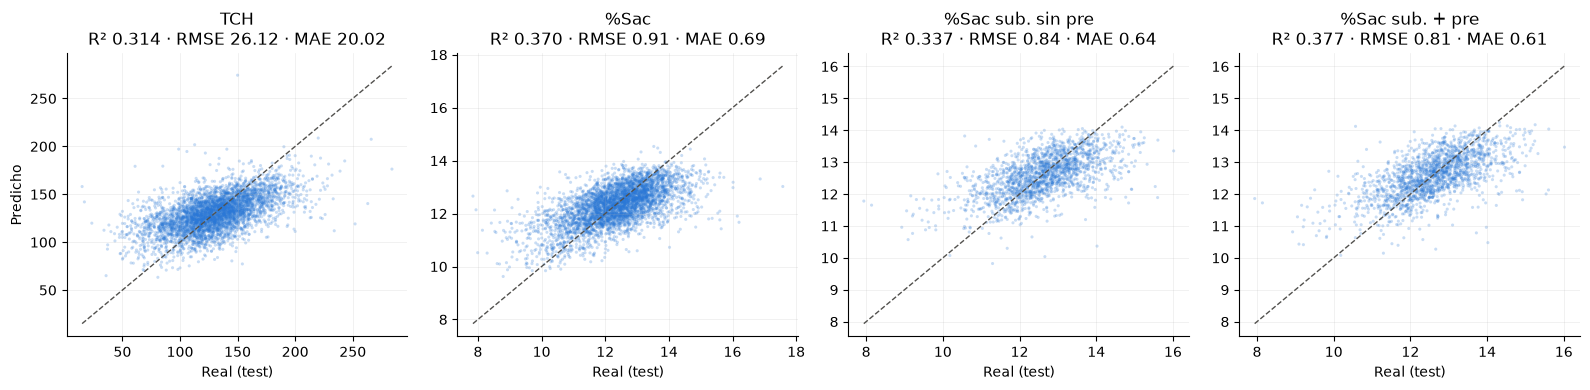

In [23]:
# Real vs. predicho en test (LinearRegression), las 4 variantes: figura para el informe
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, nombre in zip(axes, VARIANTES):
    y_te, y_pred = datos[nombre][4], res_lr[nombre]["y_pred_test"]
    ax.scatter(y_te, y_pred, s=5, alpha=0.25, color=COLORES["serie1"], edgecolors="none")
    lim = [min(y_te.min(), y_pred.min()), max(y_te.max(), y_pred.max())]
    ax.plot(lim, lim, color=COLORES["tinta"], lw=1, ls="--")
    m = metricas(y_te, y_pred)
    ax.set(title=f"{nombre}\nR² {m['R2']:.3f} · RMSE {m['RMSE']:.2f} · MAE {m['MAE']:.2f}",
           xlabel="Real (test)", ylabel="Predicho" if nombre == "TCH" else None)
    ax.grid(alpha=0.25, lw=0.5)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURAS / "reg_lineal_real_vs_pred.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusión

| Variante | Mejor benchmark | R² CV | R² test | RMSE test | MAE test |
|---|---|---|---|---|---|
| TCH | LinearRegression | 0.328 | 0.314 | 26.1 t/ha | 20.0 t/ha |
| %Sac | LinearRegression | 0.387 | 0.370 | 0.91 | 0.69 |
| %Sac sub. sin pre (2017–2021) | LinearRegression | 0.373 | 0.337 | 0.84 | 0.64 |
| %Sac sub. + pre (2017–2021) | LinearRegression | 0.417 | 0.377 | 0.81 | 0.61 |

1. **Benchmark elegido: `LinearRegression`.** Ridge y Lasso empatan (diferencias ≤ 0.005 de R²), y el lineal sin
   penalización es el más simple y el que permite inferencia directa. `log(TCH)` se descarta.
2. **Generalización:** CV y hold-out coinciden (el RMSE de test no es peor que el de CV). El lineal **no sobreajusta;
   su límite es el sesgo.** Explica ~1/3 de la varianza de TCH y ~40 % de la de %Sac, y comprime los extremos.
3. **Variables más influyentes:**
   - TCH: zona, suelo, variedad, edad al corte (+5.3 t/ha por mes), año (tendencia negativa) y semanas de madurante
     (caída monótona).
   - %Sac: cultivo orgánico, variedad, mes de cosecha, semanas de madurante (U invertida con óptimo en ~10 semanas,
     en línea con la literatura de maduración) y lluvia de los 2 meses previos (negativa).
4. **Precosecha:** +0.044 de R² CV sobre la misma población. Ayuda, pero no reemplaza al resto del modelo.
5. **Supuestos:**
   - Hay heterocedasticidad leve en TCH y colas pesadas; no afectan a la inferencia, que usa errores estándar
     cluster-robustos.
   - Hay una no linealidad leve en TCH.
   - Todo esto, junto con la compresión de los extremos, señala el límite del modelo aditivo. Modelos que capten
     interacciones (lluvia × suelo × variedad, que el enunciado menciona) y no linealidades quedan como **trabajo
     futuro**: no los exige el enunciado y no se vieron en el curso.
6. **Cambios de preprocesamiento hechos en esta etapa** (detalle en los comentarios de `src/preprocesamiento.py`):
   - tope estadístico de 36 meses para `Edad Ult Cos`;
   - último nodo del spline en 40 semanas;
   - precosecha > 25 → NaN;
   - eliminación de las colinealidades exactas del diseño lineal.